In [1]:
from pathlib import Path
import json, warnings
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.table import Table
from scipy import stats

warnings.filterwarnings("ignore")
DATA, RES, FIG = Path(".."), Path("results"), Path("figures")
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 200, "font.size": 11,
                     "axes.titlesize": 12, "axes.labelsize": 11, "legend.fontsize": 9})

header = fits.getheader(DATA / "mosaic.fits")
mask = fits.getdata(RES / "mask.fits").astype(bool)
cat = Table.read(RES / "classified_catalogue.ecsv")
comp = Table.read(RES / "completeness.ecsv")
stars = Table.read(RES / "star_count_model.ecsv")
PIX_DEG = float(header.get("PIXSCAL1", 0.258)) / 3600

BIN = 0.5
EDGES = np.arange(18.0, 26.01, BIN); CENTRES = EDGES[:-1] + BIN / 2
SDSS_STAR_LIMIT, C_MIN, FIT_C_MIN, MIN_GAL, BREAK_MAG, EUCLID = 21.5, 0.5, 0.7, 5, 22.0, 0.6
EDGE_ZONE_PX, MATCH_RADIUS = 450, 3.0
# published counts: (magnitude, galaxies per deg^2 per 0.5 mag, number of galaxies in that bin)
YASUDA = np.array([(18.25, 113.2, 16890), (18.75, 197.4, 29443), (19.25, 336.5, 50206), (19.75, 538.4, 80324),
                   (20.25, 825.9, 123213), (20.75, 1216.0, 181428), (21.25, 1627.0, 242743)])   # SDSS r*
METCALFE = np.array([(21.25, 1825, 23), (21.75, 3275, 41), (22.25, 4700, 59), (22.75, 8050, 101), (23.25, 12275, 154),
                     (23.75, 20400, 224), (24.25, 34700, 373), (24.75, 50100, 493), (25.25, 79400, 696), (25.75, 109600, 833)])
R_TO_R_SHIFT, R_TO_R_SHIFT_ERR = 0.25, 0.05      # paper's R  ->  SDSS r  (r ~ R + 0.25)

In [2]:
ny, nx = mask.shape
yy, xx = np.mgrid[0:ny, 0:nx]
edge_dist = np.minimum.reduce([xx, nx - 1 - xx, yy, ny - 1 - yy])
area_px = {"edge": int((~mask & (edge_dist < EDGE_ZONE_PX)).sum()), "inner": int((~mask & (edge_dist >= EDGE_ZONE_PX)).sum())}
area = {z: v * PIX_DEG ** 2 for z, v in area_px.items()}; total_area = sum(area.values())
# a fake galaxy can be "found" by chance on top of a real source: subtract that floor from the completeness
floor = len(cat) / sum(area_px.values()) * np.pi * MATCH_RADIUS ** 2
print(f"unmasked area: inner {area['inner']:.4f} + edge {area['edge']:.4f} = {total_area:.4f} deg^2; "
      f"chance-match floor {100 * floor:.1f}%")


def completeness_at(zone, m):
    c = comp[comp["zone"] == zone]
    corr = np.clip((np.asarray(c["C"]) - floor) / (1 - floor), 0, 1)
    return float(np.interp(m, np.asarray(c["mag"]), corr)), float(np.interp(m, np.asarray(c["mag"]), np.asarray(c["C_err"]) / (1 - floor)))

unmasked area: inner 0.0261 + edge 0.0178 = 0.0439 deg^2; chance-match floor 2.0%


In [3]:
r = np.asarray(cat["r_gal"], float)
x, y = np.asarray(cat["x"]), np.asarray(cat["y"])
zones = np.where(np.minimum.reduce([x, nx - 1 - x, y, ny - 1 - y]) < EDGE_ZONE_PX, "edge", "inner")
S, varS = np.zeros(len(CENTRES)), np.zeros(len(CENTRES))
for i, lo in enumerate(EDGES[:-1]):
    j = np.where(np.isclose(stars["mag_lo"], lo))[0]
    if len(j):
        j = j[0]
        if lo + BIN <= SDSS_STAR_LIMIT:
            S[i] = stars["n_star_sdss"][j]; varS[i] = S[i]
        else:
            S[i] = stars["n_star_model"][j]; varS[i] = S[i] + (0.5 * S[i]) ** 2   # 50% uncertainty on the extrapolation

rows = []
for i, (lo, c) in enumerate(zip(EDGES[:-1], CENTRES)):
    inb = np.isfinite(r) & (r >= lo) & (r < lo + BIN)
    num = var = 0.0; nz, cz = {}, {}
    for z in ("inner", "edge"):
        n_obj = int(np.sum(inb & (zones == z)))
        cval, cerr = completeness_at(z, c)
        s_z = S[i] * area[z] / total_area
        nz[z], cz[z] = n_obj, cval
        if cval > 0:
            num += (n_obj - s_z) / cval
            var += n_obj / cval ** 2 + varS[i] * (area[z] / total_area) ** 2 / cval ** 2 + ((n_obj - s_z) * cerr / cval ** 2) ** 2
    c_all = (cz["inner"] * area["inner"] + cz["edge"] * area["edge"]) / total_area
    n_all = nz["inner"] + nz["edge"]
    rows.append({"mag": c, "N_all": n_all, "stars_subtracted": S[i], "C": c_all, "n_per_deg2": num / total_area,
                 "n_err": np.sqrt(var) / total_area, "reliable": bool(c_all >= C_MIN and n_all - S[i] >= MIN_GAL)})
counts = Table(rows=rows)
counts.write(RES / "number_counts.ecsv", overwrite=True)
counts["n_per_deg2"].format = counts["n_err"].format = counts["stars_subtracted"].format = ".1f"
counts["C"].format = ".2f"
counts.pprint(max_lines=-1)

 mag  N_all stars_subtracted  C   n_per_deg2   n_err   reliable
----- ----- ---------------- ---- ---------- --------- --------
18.25     4              0.0 0.99       92.3      46.1    False
18.75     3              0.0 0.99       68.3      39.4    False
19.25    17              8.0 0.99      207.4     105.9     True
19.75    30              8.0 0.99      506.2     134.5     True
20.25    42             14.0 0.99      645.4     161.7     True
20.75    54             13.0 0.99      943.2     179.4     True
21.25   100             20.0 0.98     1855.9     244.1     True
21.75   138             25.2 0.96     2668.0     362.8     True
22.25   238             32.5 0.94     4955.8     483.1     True
22.75   342             42.0 0.92     7394.5     612.4     True
23.25   630             54.2 0.88    14879.7     890.9     True
23.75   831             70.0 0.80    21509.7    1255.9     True
24.25  1027             90.4 0.56    38758.1    2700.7     True
24.75  1164            116.7 0.22   1344

In [4]:
n, sn = np.asarray(counts["n_per_deg2"], float), np.asarray(counts["n_err"], float)
with np.errstate(divide="ignore", invalid="ignore"):
    logn, slog = np.log10(n), sn / (n * np.log(10))
base = (np.asarray(counts["C"]) >= FIT_C_MIN) & (np.asarray(counts["N_all"]) - S >= MIN_GAL) & np.isfinite(logn) & (n > 0)


def fit_line(sel, label):
    w = 1 / slog[sel] ** 2; A = np.c_[np.ones(sel.sum()), CENTRES[sel]]
    cov = np.linalg.inv(A.T @ (A * w[:, None])); p = cov @ (A.T @ (w * logn[sel]))
    chi2 = float(np.sum(w * (logn[sel] - A @ p) ** 2)); dof = sel.sum() - 2
    err = float(np.sqrt(cov[1, 1]) * max(1.0, np.sqrt(chi2 / dof)))
    z = (p[1] - EUCLID) / err
    print(f"  {label:7s} r {CENTRES[sel].min() - 0.25:.1f}-{CENTRES[sel].max() + 0.25:.1f}: slope {p[1]:.3f} +- {err:.3f} "
          f"(chi2/dof {chi2:.1f}/{dof}); differs from 0.6 by {abs(z):.1f} sigma")
    return {"intercept": float(p[0]), "slope": float(p[1]), "slope_err": err, "chi2": chi2, "dof": int(dof)}


fits_ = {"all": fit_line(base, "all"), "bright": fit_line(base & (CENTRES < BREAK_MAG), "bright"),
         "faint": fit_line(base & (CENTRES >= BREAK_MAG), "faint")}

  all     r 19.0-24.0: slope 0.440 +- 0.014 (chi2/dof 6.6/8); differs from 0.6 by 11.3 sigma
  bright  r 19.0-22.0: slope 0.405 +- 0.049 (chi2/dof 1.6/4); differs from 0.6 by 4.0 sigma
  faint   r 22.0-24.0: slope 0.440 +- 0.044 (chi2/dof 4.5/2); differs from 0.6 by 3.6 sigma


In [5]:
def compare(ref, label, shift=0.0, shift_err=0.0):
    rm = ref[:, 0] + shift
    ok = base & (CENTRES >= rm.min()) & (CENTRES <= rm.max())
    log_ref = np.interp(CENTRES[ok], rm, np.log10(ref[:, 1]))
    rel = np.interp(CENTRES[ok], rm, 1 / np.sqrt(ref[:, 2]))
    rel_shift = np.log(10) * np.interp(CENTRES[ok], rm, np.gradient(np.log10(ref[:, 1]), rm)) * shift_err
    ratio = n[ok] / 10 ** log_ref
    s_ratio = ratio * np.sqrt((sn[ok] / n[ok]) ** 2 + rel ** 2 + rel_shift ** 2)
    w = 1 / s_ratio ** 2; mean = float(np.sum(w * ratio) / np.sum(w))
    print(f"  vs {label}: our counts / theirs = {mean:.2f} +- {1 / np.sqrt(np.sum(w)):.2f} over {ok.sum()} bins")
    return mean


ratio_y = compare(YASUDA, "Yasuda et al. 2001")
ratio_m = compare(METCALFE, "Metcalfe et al. 2001", R_TO_R_SHIFT, R_TO_R_SHIFT_ERR)
json.dump({"area_deg2": total_area, "fits": fits_, "ratio_yasuda": ratio_y, "ratio_metcalfe": ratio_m},
          open(RES / "number_counts_summary.json", "w"), indent=1)

  vs Yasuda et al. 2001: our counts / theirs = 0.90 +- 0.08 over 5 bins
  vs Metcalfe et al. 2001: our counts / theirs = 1.31 +- 0.08 over 5 bins


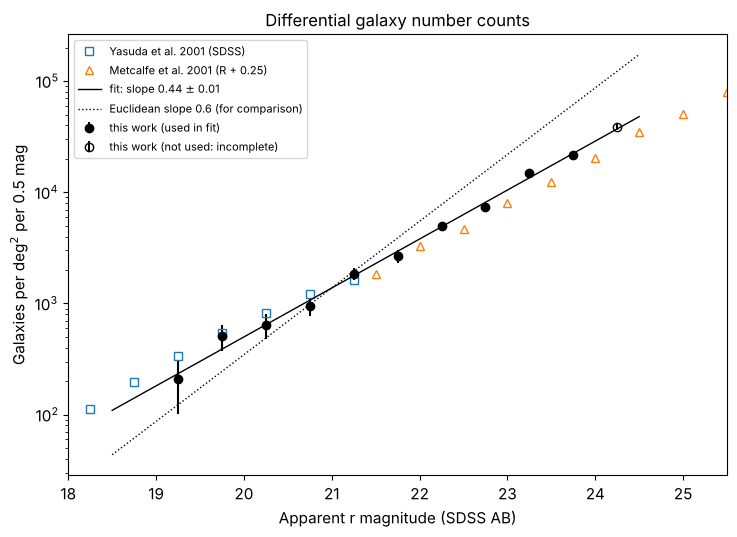

In [6]:
fig, ax = plt.subplots(figsize=(7.5, 5.5))
rel = np.asarray(counts["reliable"]) & (n > 0)
ax.errorbar(CENTRES[base], n[base], sn[base], fmt="o", color="k", label="this work (used in fit)")
other = rel & ~base
ax.errorbar(CENTRES[other], n[other], sn[other], fmt="o", mfc="none", color="k", label="this work (not used: incomplete)")
ax.plot(YASUDA[:, 0], YASUDA[:, 1], "s", color="C0", mfc="none", label="Yasuda et al. 2001 (SDSS)")
ax.plot(METCALFE[:, 0] + R_TO_R_SHIFT, METCALFE[:, 1], "^", color="C1", mfc="none", label="Metcalfe et al. 2001 (R + 0.25)")
mm = np.linspace(18.5, 24.5, 50)
ax.plot(mm, 10 ** (fits_["all"]["intercept"] + fits_["all"]["slope"] * mm), "k-", lw=1,
        label=f"fit: slope {fits_['all']['slope']:.2f} $\\pm$ {fits_['all']['slope_err']:.2f}")
ax.plot(mm, 10 ** (fits_["all"]["intercept"] + fits_["all"]["slope"] * 21 + EUCLID * (mm - 21)), "k:", lw=1,
        label="Euclidean slope 0.6 (for comparison)")
ax.set_yscale("log"); ax.set_xlim(18, 25.5)
ax.set_xlabel("Apparent r magnitude (SDSS AB)"); ax.set_ylabel(r"Galaxies per deg$^2$ per 0.5 mag")
ax.set_title("Differential galaxy number counts"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "06_number_counts.png"); plt.show()